# 6 · NEST and Brian2

Run the toy network model on both simulators and compare them, in Python. About five minutes.

Open this notebook in your project folder ([tutorial 1](1_first_run.md)). You need Brian2 (`pip install brian2`) and its models in the project, `extensions/brian2/`: `init` copies them when Brian2 is installed; if you installed it later, run `microcircuit-lab init .` in the project, which adds what is missing.

## Run on both

In [1]:
from microcircuit_lab import Simulation, read_run

runs = {}
for simulator in ["nest", "brian2"]:
    simulation = Simulation.from_yaml(network_name="toy", backend=simulator)
    simulation.run()
    runs[simulator] = read_run(simulation.output_dir)


             -- N E S T --

 Copyright (C) 2004 The NEST Initiative

 Version: 3.10.0
 Built  : Jun 10 2026 07:01:20

 This program is provided AS IS and comes with NO WARRANTY.
 See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

[INFO] [2026-11-20 20:53:33] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:33] Preparing 1012 nodes for simulation.


[INFO] [2026-11-20 20:53:33] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:33] Simulation finished.


INFO       Cache size for target 'cython': 1464 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/shimoura/.cython/brian_extensions' directory. [brian2]


Brian2's runtime device runs on one thread; local_num_threads=4 is used only with the cpp_standalone device.


`backend=` picks the simulator; the files are the same. Brian2 compiles the network the first time, which takes a minute or so; later runs are quicker.

## Compare

In [2]:
from microcircuit_lab.analysis import (
    compute_population_firing_rates,
    compute_population_isi_cv,
)

for simulator, run in runs.items():
    rates = compute_population_firing_rates(run, begin=200.0)
    cv = compute_population_isi_cv(run, begin=200.0)
    print(f"{simulator:7s} rate E {rates['E']:5.1f}  I {rates['I']:5.1f} spikes/s    "
          f"ISI CV E {cv['E']:.2f}  I {cv['I']:.2f}")

nest    rate E  20.3  I  20.8 spikes/s    ISI CV E 0.41  I 0.39
brian2  rate E  20.8  I  20.8 spikes/s    ISI CV E 0.41  I 0.43


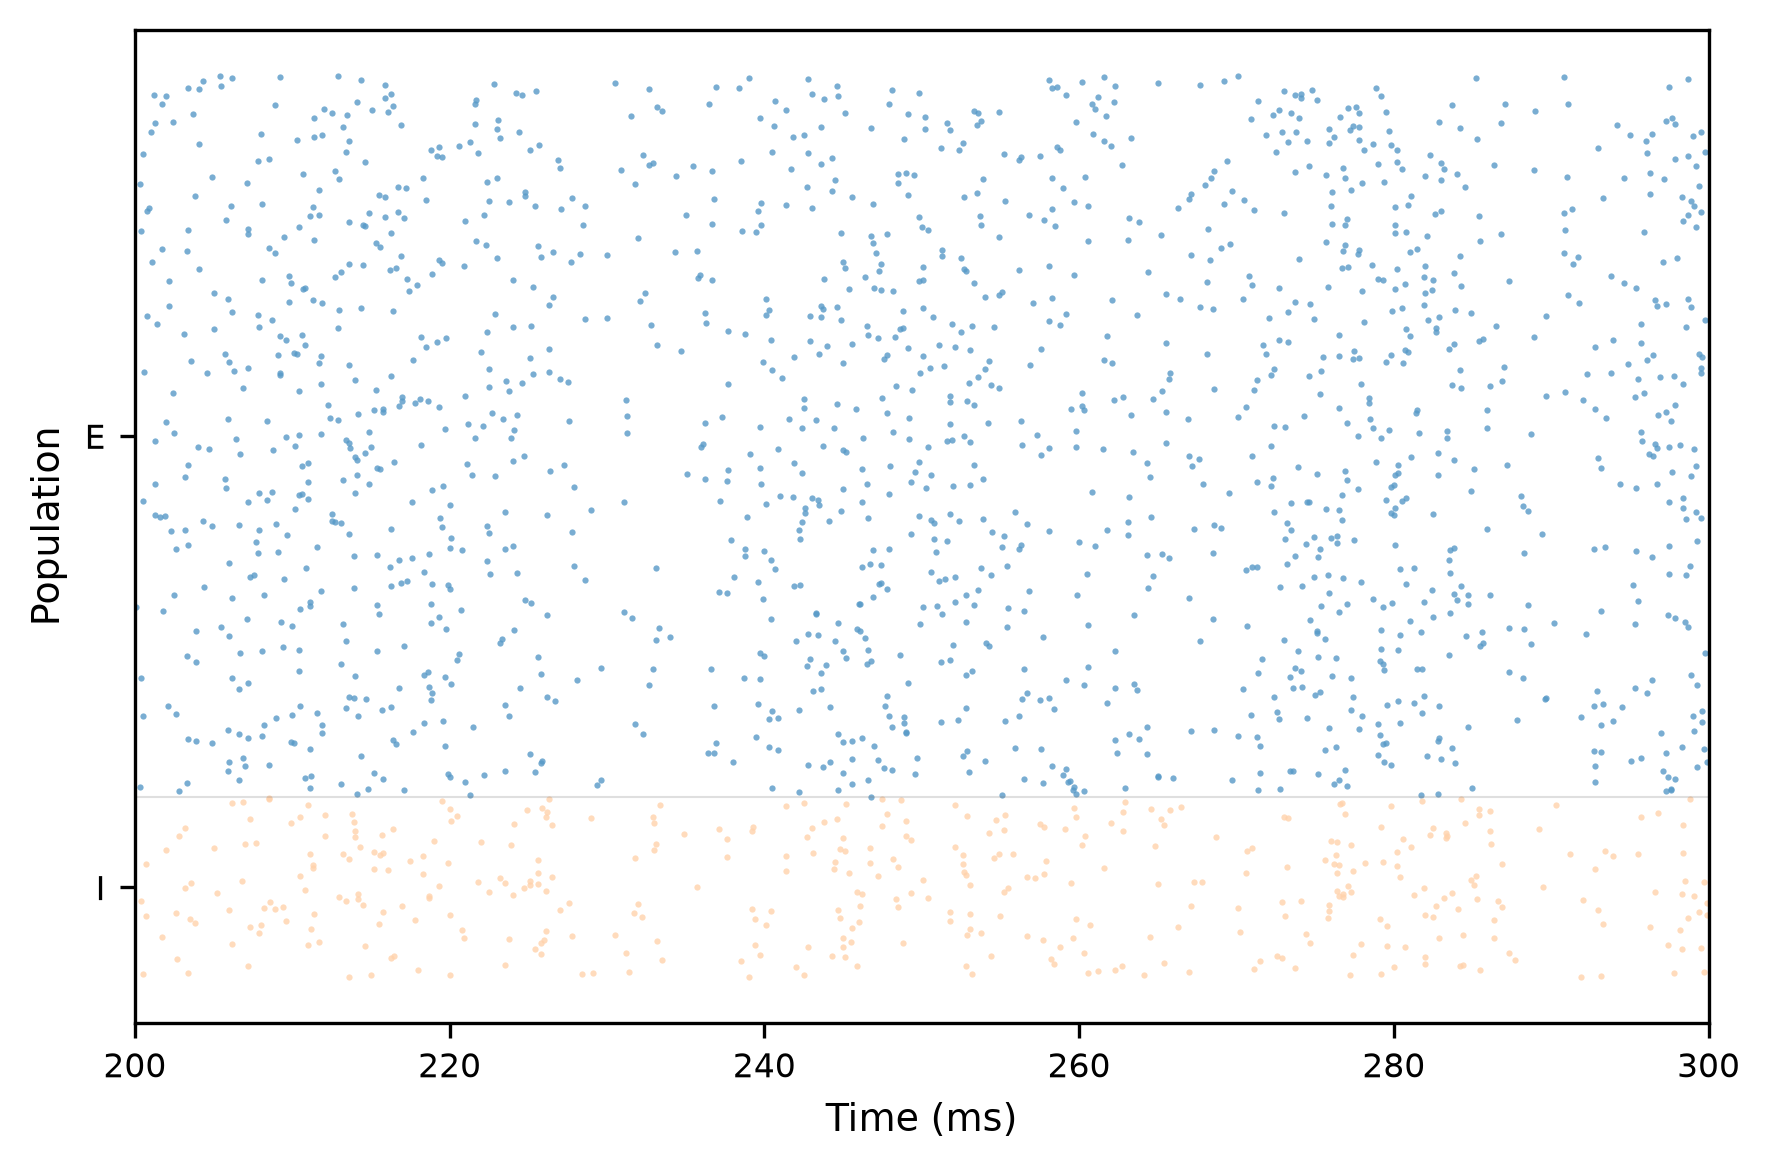

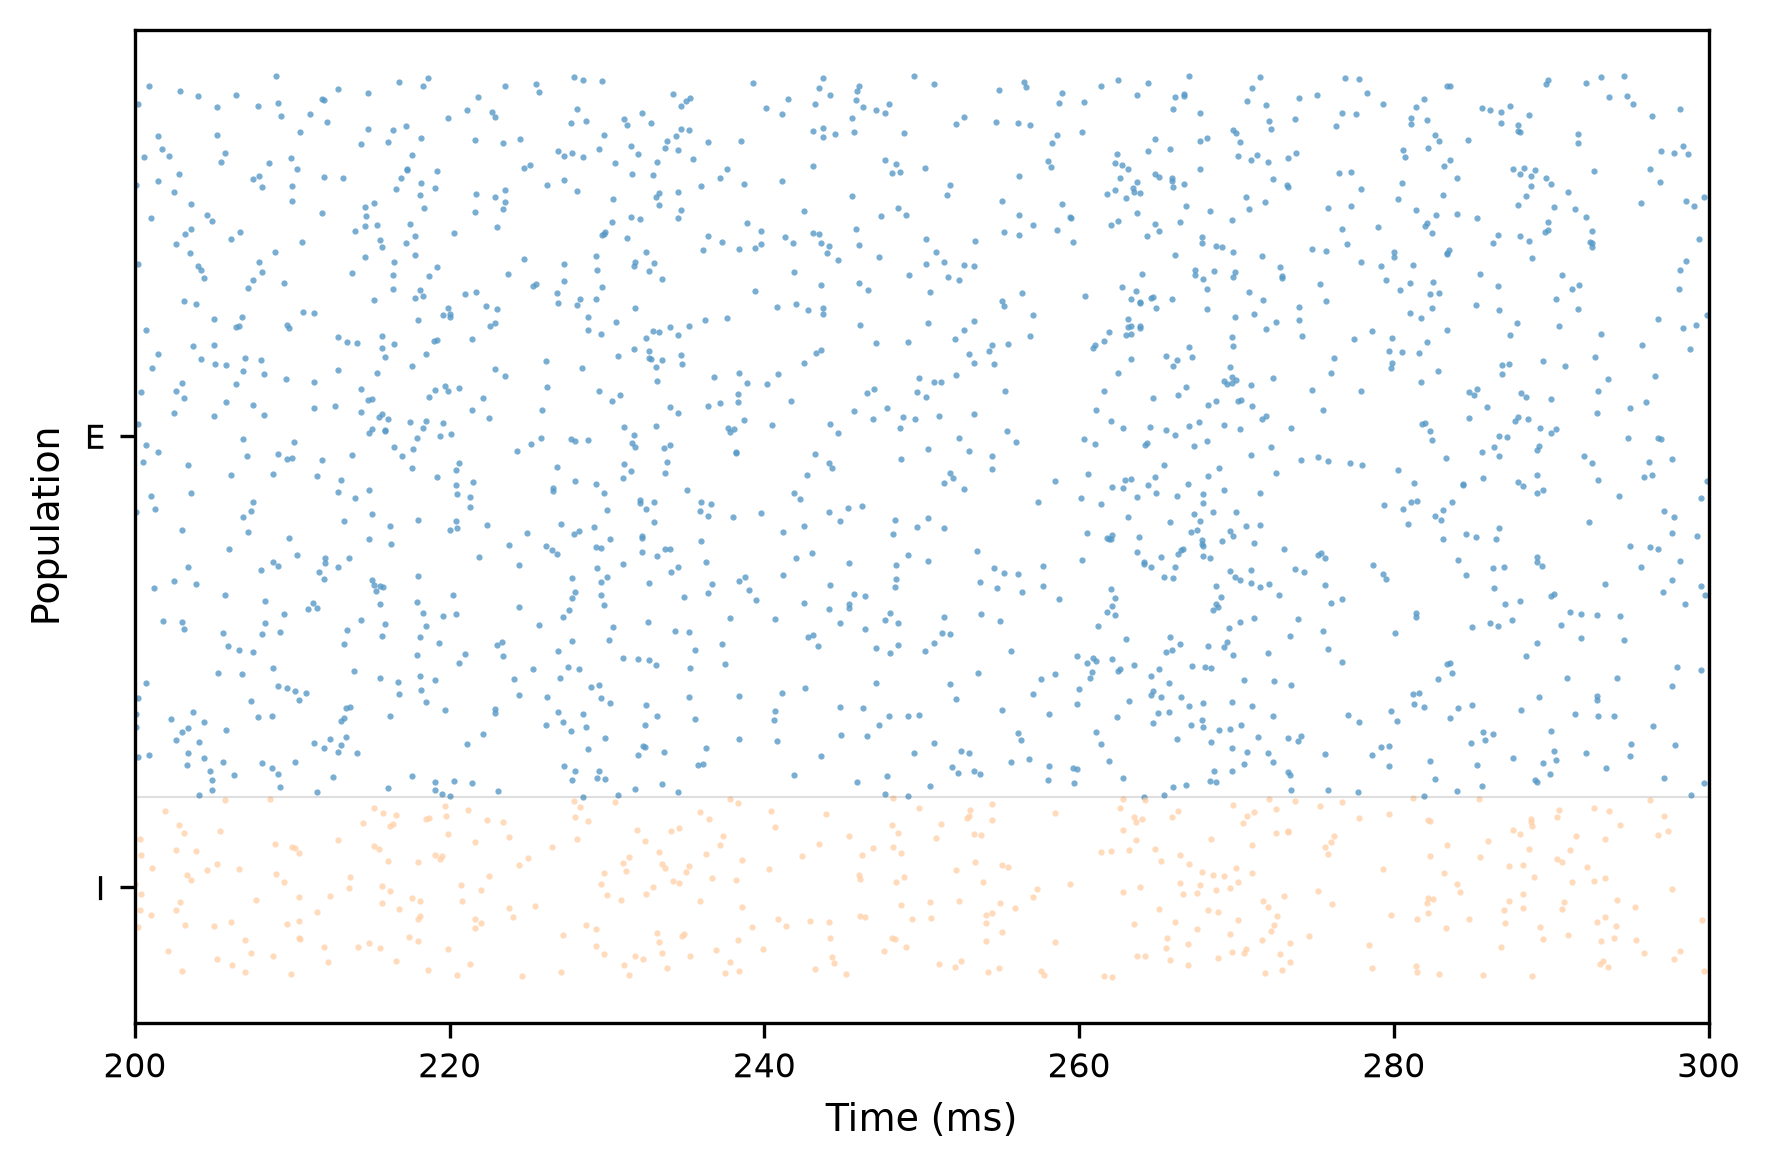

In [3]:
from microcircuit_lab.analysis import plot_raster

for simulator, run in runs.items():
    fig, ax = plot_raster(run, begin=200.0, end=300.0)
    ax.set_title(simulator)

The two give the same statistics (rates, ISI CV), not the same spikes: each simulator draws its own random numbers.

Brian2 has no neuron models of its own: it reads the equations of each model from `extensions/brian2/`, one Python file per model. Writing one for a model of your own: [Brian2](../brian2.md#models-of-your-own).